# Stock direction report

Can a model predict whether a stock closes higher tomorrow, using only information available at today's close, better than simple rules can?

This notebook is a **template**. `python run.py NVDA` fills in the settings below and saves the finished report as `reports/NVDA.ipynb`. To run it by hand, change `TICKER` in the next cell and run all cells.

**Why direction, not price:** tomorrow's price is almost always close to today's, so a "predicted vs. actual price" chart looks impressive even for a model that has learned nothing. Up-or-down is a much harder test to fake.

**What "honest" means here:**
1. **No peeking at the future.** Every feature uses only data up to today's close, and the model is always tested on years it never saw during training.
2. **Real baselines.** Beating a coin flip is easy because stocks rise more often than they fall. The bar is the rule "always predict up."
3. **Noise check.** Every accuracy comes with a range showing how much could be luck.
4. **Money check.** A backtest with trading costs, compared against simply buying and holding, plus a luck check.
5. **Pipeline checks.** The same code must find nothing in pure noise, and must find a pattern that is planted on purpose.

In [1]:
# Settings (run.py replaces these)
TICKER = "SPY"
START = "2005-01-01"
# First year to predict. None = automatic: the first year with about 4 years of history before it
FIRST_TEST_YEAR = None
# Cost per buy or sell in the backtest: 0.001 = 0.1%
COST = 0.001

In [2]:
# Parameters
TICKER = "AAPL"
START = "2005-01-01"
FIRST_TEST_YEAR = None
COST = 0.001


In [3]:
import sys
from pathlib import Path

# Find the project folder, whether this runs from the project, notebooks/ or reports/
ROOT = Path.cwd()
if ROOT.name in ("notebooks", "reports"):
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import pandas as pd
from cycler import cycler
from IPython.display import Markdown, display

pd.set_option("display.float_format", "{:.4f}".format)
plt.rcParams["figure.figsize"] = (11, 4)
# Same colors in every report: blue, orange, aqua, yellow
plt.rcParams["axes.prop_cycle"] = cycler(color=["#2a78d6", "#eb6834", "#1baf7a", "#eda100"])

from src.data import load_prices, make_random_walk, make_planted_pattern
from src.features import FEATURES, ALL_FEATURES, build_dataset
from src.evaluate import (get_models, first_test_year, walk_forward, baseline_predictions,
                          accuracy_table, accuracy_by_year, backtest_table, luck_check)
from src.report import summarize, save_summary

display(Markdown(f"# {TICKER}: can a model predict tomorrow's direction?"))

# AAPL: can a model predict tomorrow's direction?

## 1. Data

Daily prices, adjusted for dividends and splits. The first run downloads them; later runs load the saved copy in `data/`. `python run.py TICKER --refresh` pulls the latest days.

If the data was downloaded while the US market was still open, today's row is left out automatically: its "close" isn't final yet.

5,478 trading days, 2005-01-03 to 2026-10-12


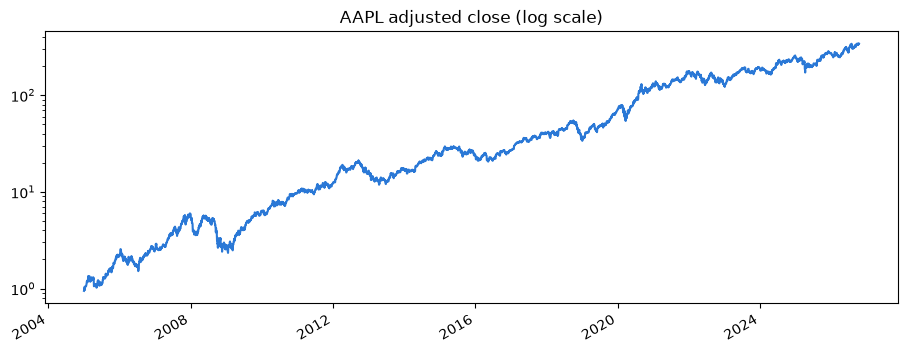

In [4]:
prices = load_prices(TICKER, START)
print(f"{len(prices):,} trading days, {prices.index[0].date()} to {prices.index[-1].date()}")

ax = prices["Close"].plot(logy=True, title=f"{TICKER} adjusted close (log scale)")
ax.set_xlabel("")
plt.show()

In [5]:
daily_ret = prices["Close"].pct_change().dropna()
growth = prices["Close"].iloc[-1] / prices["Close"].iloc[0]
print(f"Share of up days: {(daily_ret > 0).mean():.1%}")

display(Markdown(
    f"**A note on hindsight.** \\$1 in {TICKER} on {prices.index[0].date()} grew to "
    f"\\${growth:,.2f} by {prices.index[-1].date()}. If {TICKER} was chosen because it is a "
    f"well-known success today, buy-and-hold looks good partly in hindsight: nobody in "
    f"{prices.index[0].year} knew how it would turn out. This affects the buy-and-hold "
    f"comparison, not the model tests: the models still had to predict each day using only the past."
))

Share of up days: 53.1%


**A note on hindsight.** \$1 in AAPL on 2005-01-03 grew to \$360.25 by 2026-10-12. If AAPL was chosen because it is a well-known success today, buy-and-hold looks good partly in hindsight: nobody in 2005 knew how it would turn out. This affects the buy-and-hold comparison, not the model tests: the models still had to predict each day using only the past.

The share of up days is the accuracy of "always predict up." Any model has to beat it, not 50%, to show it has learned something.

## 2. Features and label

Eight features are calculated. The models use five of them, one per idea:

| Feature | Meaning | Used by the models? |
|---|---|---|
| `ret_1d` | Return over the last day | Yes |
| `ret_5d` | Return over the last 5 days (one week) | Yes |
| `dist_ma50` | How far today's price is above or below its 50-day average (longer trend) | Yes |
| `vol_20d` | How jumpy daily returns were over the last 20 days (risk) | Yes |
| `volume_ratio` | Today's volume compared with its 20-day average (activity) | Yes |
| `ret_10d`, `ret_20d` | Return over the last 10 and 20 days | No: overlap with the kept features |
| `dist_ma10` | Distance from the 10-day average | No: nearly a copy of `ret_5d` |

The **label** (`target`) is 1 if tomorrow's close is higher than today's, else 0. `next_ret` is tomorrow's return, kept for the backtest.

In [6]:
data = build_dataset(prices)
if FIRST_TEST_YEAR is None:
    FIRST_TEST_YEAR = first_test_year(data)
print(f"First test year: {FIRST_TEST_YEAR}")
data.head()

First test year: 2010


,ret_1d,ret_5d,ret_10d,ret_20d,dist_ma10,dist_ma50,vol_20d,volume_ratio,next_ret,target
Date,,,,,,,,,,
2005-03-15,0.0159,0.0106,-0.0796,-0.0320,-0.0076,0.0530,0.0255,-0.5085,0.0054,1
2005-03-16,0.0054,0.0465,-0.0666,-0.0684,0.0049,0.0535,0.0232,-0.2686,0.0260,1
2005-03-17,0.0260,0.0608,0.0110,-0.0625,0.0299,0.0752,0.0236,-0.1210,0.0168,1
2005-03-18,0.0168,0.0668,0.0035,-0.0215,0.0468,0.0873,0.0233,0.0643,0.0172,1
2005-03-21,0.0172,0.0838,0.0222,0.0068,0.0624,0.0997,0.0235,-0.3650,-0.0199,0


### Why only five? Overlapping features

When two features measure nearly the same thing, a model can split weight between them or give them opposite weights that cancel out, so you can no longer read what it learned. Correlation runs from -1 to 1; values near ±1 mean two features move together.

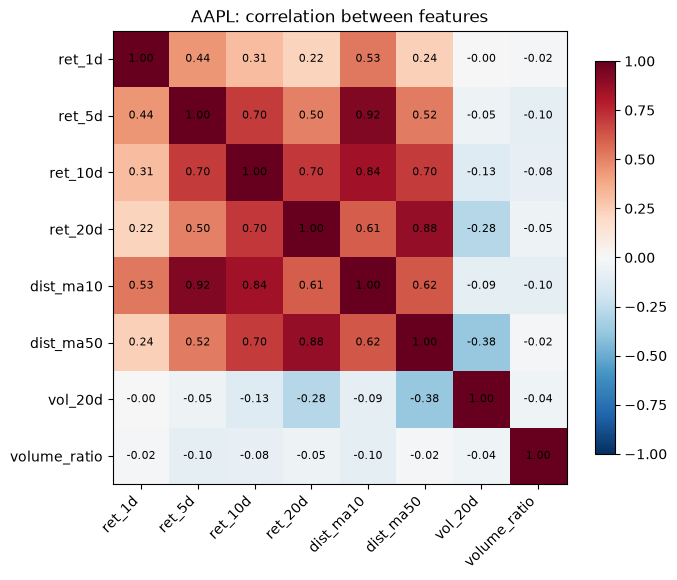

In [7]:
corr = data[ALL_FEATURES].corr()
fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(ALL_FEATURES)), ALL_FEATURES, rotation=45, ha="right")
ax.set_yticks(range(len(ALL_FEATURES)), ALL_FEATURES)
for i in range(len(ALL_FEATURES)):
    for j in range(len(ALL_FEATURES)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
fig.colorbar(im, ax=ax, shrink=0.8)
ax.set_title(f"{TICKER}: correlation between features")
plt.tight_layout()
plt.show()

How strongly does each feature relate to tomorrow's return? Expect numbers close to zero, which is the first hint of how hard this is.

In [8]:
data[ALL_FEATURES].corrwith(data["next_ret"]).sort_values().to_frame("correlation with next-day return")

,correlation with next-day return
ret_1d,-0.0238
dist_ma10,-0.0176
ret_10d,-0.0137
vol_20d,-0.0106
ret_5d,-0.0031
dist_ma50,0.0020
ret_20d,0.0042
volume_ratio,0.0239


## 3. Walk-forward testing

A random train/test split would let the model train on 2020 and then "predict" 2015, which is peeking at the future. Instead:

- Train on all years before the first test year, predict every day of that year.
- Add that year to the training data, predict the next year.
- ...and so on up to today.

Every prediction is made by a model that only saw earlier years, just like it would be used in real life.

In [9]:
model_preds = {}
for name, model in get_models().items():
    model_preds[name] = walk_forward(model, data, FIRST_TEST_YEAR)
    print(f"{name}: done")

test = data[data.index.year >= FIRST_TEST_YEAR]
baselines = baseline_predictions(test)

all_preds = {name: p["pred"] for name, p in model_preds.items()}
all_preds.update({name: baselines[name] for name in baselines})
print(f"Test period: {test.index[0].date()} to {test.index[-1].date()} ({len(test):,} days)")

Logistic regression: done


Gradient boosting: done
Test period: 2010-01-04 to 2026-10-09 (4,218 days)


## 4. Results: accuracy

How to read this table:
- **range low / range high**: the 95% range. Two methods whose ranges overlap heavily can't really be told apart.
- **predicted up**: if a model says "up" on nearly every day, it has mostly learned "always up," not a real pattern.
- **p-value vs coin flip**: small values mean it beats coin flipping. Notice "Always up" passes this test too, which is why it's a weak test.
- **beats always-up?**: the honest test. True only if the model is better than "always up" by more than noise.

In [10]:
accuracy_table(all_preds, test["target"])

,accuracy,range low,range high,predicted up,p-value vs coin flip,beats always-up?
Logistic regression,0.5294,0.5143,0.5445,0.9322,0.0001,False
Gradient boosting,0.5135,0.4984,0.5286,0.6925,0.0409,False
Coin flip,0.4931,0.4780,0.5082,0.5038,0.8182,False
Always up,0.5308,0.5158,0.5459,1.0000,0.0000,False
Repeat last move,0.5012,0.4861,0.5163,0.5308,0.4449,False


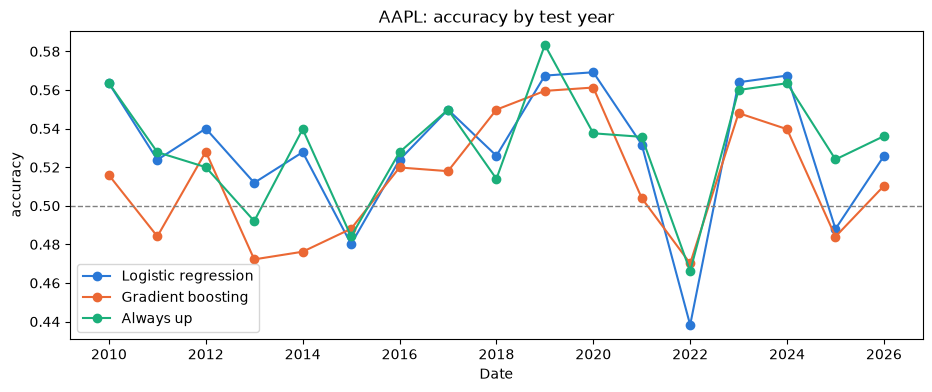

In [11]:
by_year = accuracy_by_year(all_preds, test["target"])
ax = by_year[list(model_preds) + ["Always up"]].plot(marker="o", title=f"{TICKER}: accuracy by test year")
ax.axhline(0.5, color="grey", linestyle="--", linewidth=1)
ax.set_ylabel("accuracy")
plt.show()

Questions to ask yourself here: does a model beat "always up" consistently, or only in a few years? Which years are bad, and what happened in markets then?

### Do the three left-out features help?

The same walk-forward test with all eight features. If the left-out features only repeated what the kept ones already say, accuracy should barely change.

In [12]:
rows = {}
for name, model in get_models().items():
    for label, feats in [("5 features", FEATURES), ("all 8 features", ALL_FEATURES)]:
        p = walk_forward(model, data, FIRST_TEST_YEAR, features=feats)
        rows[(name, label)] = {"accuracy": (p["pred"] == test["target"]).mean(),
                               "predicted up": p["pred"].mean()}
pd.DataFrame(rows).T

accuracy  predicted up
Logistic regression 5 features        0.5294        0.9322
                    all 8 features    0.5204        0.8743
Gradient boosting   5 features        0.5135        0.6925
                    all 8 features    0.5216        0.6754

## 5. Backtest: would it have made money?

Strategy: at each close, hold the stock into tomorrow if the model predicts up, otherwise sit in cash. Each buy or sell costs `COST`. Compared against buying once and holding.

In [13]:
positions = {"Buy and hold": pd.Series(1, index=test.index)}
positions.update({name: p["pred"] for name, p in model_preds.items()})

stats, daily_returns = backtest_table(positions, test["next_ret"], cost=COST)
stats

,total return,annual return,annual volatility,Sharpe ratio,max drawdown,days in market,trades
Buy and hold,52.2154,0.2680,0.2809,0.9862,-0.4380,1.0000,1
Logistic regression,28.9851,0.2253,0.2583,0.9162,-0.4758,0.9322,339
Gradient boosting,3.7024,0.0969,0.2305,0.5162,-0.5019,0.6925,1413


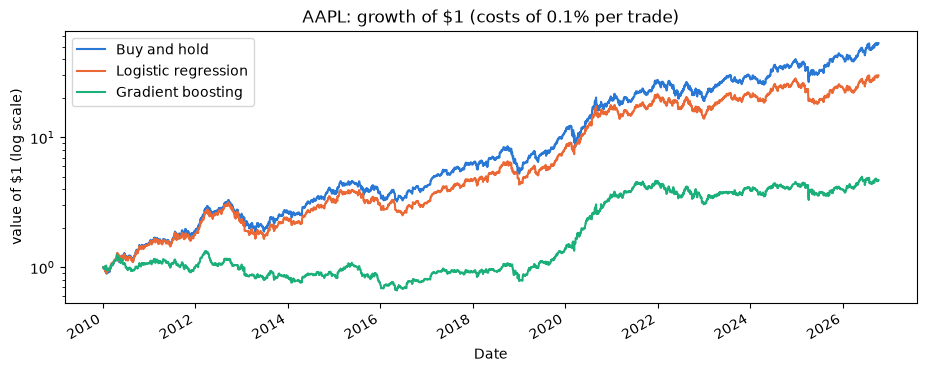

In [14]:
ax = (1 + daily_returns).cumprod().plot(logy=True, title=f"{TICKER}: growth of $1 (costs of {COST:.1%} per trade)")
ax.set_ylabel("value of $1 (log scale)")
plt.show()

Trading costs matter. Here's the same backtest at different cost levels. A strategy that only wins when trading is free isn't a real edge.

In [15]:
rows = {}
for cost in [0, 0.0005, 0.001, 0.002]:
    s, _ = backtest_table(positions, test["next_ret"], cost=cost)
    rows[f"{cost:.2%}"] = s["annual return"]
pd.DataFrame(rows).rename_axis(columns="cost per trade")

cost per trade,0.00%,0.05%,0.10%,0.20%
Buy and hold,0.2681,0.2680,0.2680,0.2679
Logistic regression,0.2504,0.2378,0.2253,0.2007
Gradient boosting,0.1936,0.1442,0.0969,0.0080


### Is any edge just luck?

A strategy that sits in cash on a few days can beat buy-and-hold just by happening to miss some bad days. To check, keep the same number of cash days but pick them at random, 2,000 times. The random versions trade for free, which is generous to luck, so this is a strict test.

- **share of random >=**: how often a random choice of cash days did at least as well. Around 0.05 or less is hard to explain by luck; much higher means the result is easy to get by chance.
- **Biggest days avoided / missed**: if a handful of extreme days drive the result, it's fragile. One lucky day in a crash can make a strategy look good for a decade.

In [16]:
luck = {}
for name, p in model_preds.items():
    if (p["pred"] == 0).any():
        luck[name] = luck_check(p["pred"], test["next_ret"], cost=COST)
if luck:
    display(pd.DataFrame(luck).T)
else:
    print("Both models stayed in the market every day: nothing to compare with random cash days.")

for name, p in model_preds.items():
    cash_days = test.loc[p["pred"] == 0, "next_ret"].sort_values()
    if len(cash_days) == 0:
        continue
    print(f"\n{name}: {len(cash_days)} days in cash")
    print("  Biggest drops avoided:", ", ".join(f"{d.date()} {r:+.1%}" for d, r in cash_days.head(3).items()))
    print("  Biggest rises missed: ", ", ".join(f"{d.date()} {r:+.1%}" for d, r in cash_days.tail(3)[::-1].items()))

,annual return,random median,share of random >=,cash days
Logistic regression,0.2253,0.2479,0.8675,286.0000
Gradient boosting,0.0969,0.1785,0.9890,1297.0000



Logistic regression: 286 days in cash
  Biggest drops avoided: 2020-03-13 -12.9%, 2020-02-26 -6.5%, 2020-03-19 -6.3%
  Biggest rises missed:  2025-04-08 +15.3%, 2020-03-23 +10.0%, 2020-02-28 +9.3%

Gradient boosting: 1297 days in cash
  Biggest drops avoided: 2020-03-13 -12.9%, 2018-11-01 -6.6%, 2016-01-26 -6.6%
  Biggest rises missed:  2012-04-24 +8.9%, 2010-05-07 +7.7%, 2024-06-10 +7.3%


## 6. Checking the pipeline itself

Two tests on fake prices, run through exactly the same code as the real data. Together they show the "detector" works both ways.

### 6a. Pure noise: the models should find nothing

Fake prices where every day is pure chance. Nothing can be predicted, so the models should land close to "always up." If a model clearly beats it here, the code is leaking future information and the real results can't be trusted.

In [17]:
def check_on_fake_prices(fake_prices):
    fake = build_dataset(fake_prices)
    start_year = first_test_year(fake)
    fake_test = fake[fake.index.year >= start_year]
    preds = {name: walk_forward(m, fake, start_year)["pred"] for name, m in get_models().items()}
    preds["Always up"] = pd.Series(1, index=fake_test.index)
    preds["Repeat last move"] = (fake_test["ret_1d"] > 0).astype(int)
    return accuracy_table(preds, fake_test["target"])

check_on_fake_prices(make_random_walk(n_days=len(prices), start=prices.index[0]))

,accuracy,range low,range high,predicted up,p-value vs coin flip,beats always-up?
Logistic regression,0.5047,0.4895,0.5198,0.3976,0.2782,False
Gradient boosting,0.5030,0.4878,0.5182,0.4601,0.3551,False
Always up,0.5028,0.4876,0.5179,1.0000,0.3667,False
Repeat last move,0.4965,0.4814,0.5117,0.5030,0.6788,False


### 6b. A planted pattern: the models should find it

Fake prices with a pattern built in on purpose: after an up day, the next day is down 60% of the time, and after a down day, the next day is up 60% of the time. Up and down days are equally common, so "always up" scores about 50%, while a model that learns "bet against yesterday's move" should score about 60%. Both models should show **True** in "beats always-up?".

This is what makes the real-data result meaningful: the same code finds a pattern when one exists, so finding nothing in real prices means there was nothing to find.

In [18]:
check_on_fake_prices(make_planted_pattern(n_days=len(prices), start=prices.index[0]))

,accuracy,range low,range high,predicted up,p-value vs coin flip,beats always-up?
Logistic regression,0.5948,0.5799,0.6097,0.4996,0.0000,True
Gradient boosting,0.5852,0.5702,0.6001,0.5068,0.0000,True
Always up,0.4956,0.4804,0.5107,1.0000,0.7218,False
Repeat last move,0.3954,0.3806,0.4102,0.4958,1.0000,False


## 7. What did logistic regression learn?

Weights from a model fitted on all the data. Features were scaled first, so the sizes are comparable: positive means "this pushes toward predicting up." With five non-overlapping features, each bar can be read on its own. This describes the model; it doesn't prove the patterns are real.

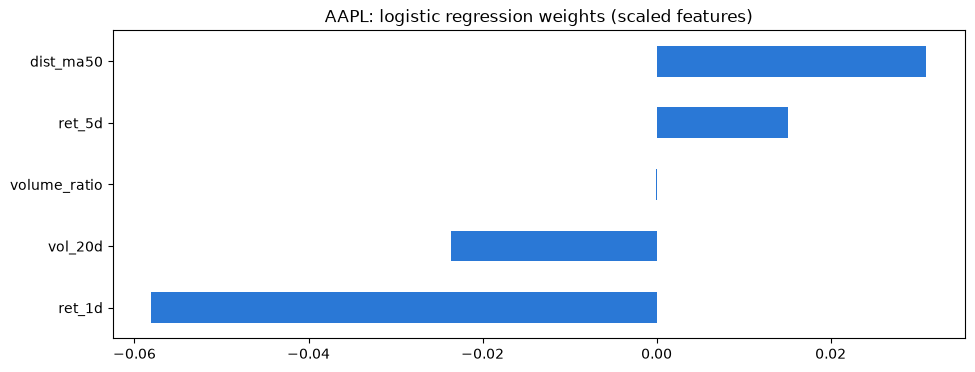

In [19]:
logreg = get_models()["Logistic regression"].fit(data[FEATURES], data["target"])
weights = pd.Series(logreg[-1].coef_[0], index=FEATURES).sort_values()
weights.plot.barh(title=f"{TICKER}: logistic regression weights (scaled features)")
plt.show()

## 8. Summary for the comparison

The headline numbers, saved to `reports/summaries/` so `python run.py` can compare several stocks side by side. **p-value vs always up** is the chance of an accuracy this high if the model were no better than "always up."

In [20]:
summary = summarize(TICKER, test, model_preds, cost=COST, luck=luck)
path = save_summary(summary)
print(f"Saved {path.relative_to(ROOT)}")
pd.DataFrame(summary["models"]).T

Saved reports/summaries/AAPL.json


,accuracy,predicted up,p-value vs always up,annual return,Sharpe ratio,max drawdown,cash days,share of random >=
Logistic regression,0.5294,0.9322,0.5796,0.2253,0.9162,-0.4758,286.0000,0.8675
Gradient boosting,0.5135,0.6925,0.9883,0.0969,0.5162,-0.5019,1297.0000,0.9890


## 9. Conclusions

*Write this in your own words after reading the results. It's the most important part for a portfolio reader.* Some prompts:

- Did either model beat "always up" beyond the noise range? By how much?
- Was any edge consistent across years, or concentrated in a few?
- Did the backtest beat buy-and-hold after costs? On return, on Sharpe ratio, on drawdown? Did it pass the luck check?
- What did the two pipeline checks show, and why do they matter?
- How much of buy-and-hold's result is hindsight?